
Genes found: ['CD74', 'KRT13', 'COL1A1', 'FTH1', 'FN1', 'SCEL', 'MMP2', 'STAT1', 'COL17A1', 'KRT5', 'GBP1', 'SPARC', 'CXCL10', 'SPRR3', 'COL3A1', 'CEACAM5', 'TGM3', 'CLDN4', 'KRT15', 'GPX2', 'FXYD3', 'TAP1', 'CSTA', 'KRT14']

Cell types: ['Immune Stromal Interface', 'Metabolic-like IABTS', 'Immune-adapted IABTS', 'Differentiated Tumor Core']
Processing cell type: Immune Stromal Interface, number of cells: 77109
Processing cell type: Metabolic-like IABTS, number of cells: 162836
Processing cell type: Immune-adapted IABTS, number of cells: 46249
Processing cell type: Differentiated Tumor Core, number of cells: 68969


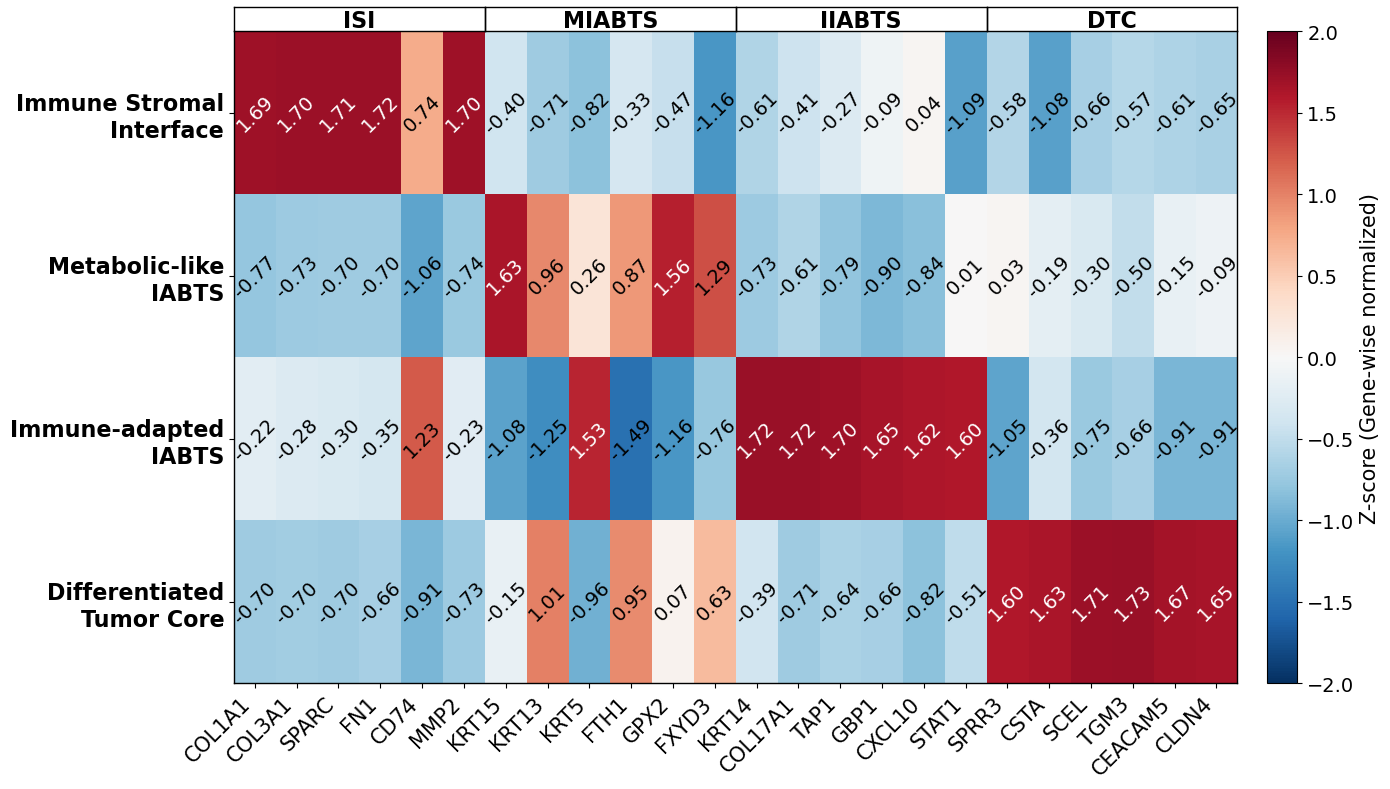

In [5]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, issparse
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ================= Font size settings =================
# Manually adjust the parameters below to change font sizes for different elements
FONT_SIZES = {
    'group_label': 16,      # Group label font size (e.g., "ISI", "MIABTS")
    'gene_label': 15,        # Gene name font size (x-axis labels)
    'cell_type_label': 16,  # Cell type font size (y-axis labels)
    'colorbar_label': 15,   # Colorbar label font size
    'colorbar_ticks': 14,    # Colorbar tick font size
    'value_text': 14         # Value text font size inside the heatmap
}

# ================= Select marker_set for display based on supplementary results =================

marker_set = {
    "Immune Stromal Interface": ["COL1A1", "COL3A1", "SPARC", "FN1", "CD74", "MMP2"],
    "Metabolic-like IABTS": ["KRT15", "KRT13","KRT5", "FTH1", "GPX2", "FXYD3"],
    "Immune-adapted IABTS": ["KRT14", "COL17A1", "TAP1", "GBP1", "CXCL10", "STAT1"],
    "Differentiated Tumor Core": ["SPRR3", "CSTA", "SCEL", "TGM3", "CEACAM5", "CLDN4"]
}

# ================= Data preprocessing =================

epi_merged_normalized = sc.read("./h5ad/epi_merged.h5ad")
sc.pp.normalize_total(epi_merged_normalized, target_sum=1e4)
sc.pp.log1p(epi_merged_normalized)

# ================= Calculate mean expression =================

all_genes = []
for genes in marker_set.values():
    all_genes.extend(genes)
all_genes = list(set(all_genes))

available_genes = [gene for gene in all_genes if gene in epi_merged_normalized.var_names]
missing_genes = [gene for gene in all_genes if gene not in epi_merged_normalized.var_names]

if missing_genes:
    print(f"Warning: The following genes are not present in adata: {missing_genes}")

if len(available_genes) == 0:
    print("Error: No marker genes found!")
    exit()

print(f"\nGenes found: {available_genes}")

cell_types = epi_merged_normalized.obs['type'].unique()
cell_types = [ct for ct in cell_types if ct != 'Others']
print(f"\nCell types: {cell_types}")

expression_data = []
for cell_type in cell_types:
    mask = epi_merged_normalized.obs['type'] == cell_type
    adata_sub = epi_merged_normalized[mask]
    
    print(f"Processing cell type: {cell_type}, number of cells: {adata_sub.n_obs}")
    
    row = {'Cell_Type': cell_type}
    for gene in available_genes:
        gene_expr = adata_sub[:, gene].X
        if issparse(gene_expr):
            mean_val = np.mean(gene_expr.toarray())
        else:
            mean_val = np.mean(gene_expr)
        row[gene] = mean_val
    expression_data.append(row)

mean_expression = pd.DataFrame(expression_data)
mean_expression.set_index('Cell_Type', inplace=True)


ordered_genes = []
for group, genes in marker_set.items():
    for gene in genes:
        if gene in available_genes:
            ordered_genes.append(gene)

pivot_data = mean_expression[ordered_genes].copy()

# ================= Z-score normalization =================

original_data = pivot_data.copy()

# Z-score standardize each column (each gene)
scaler = StandardScaler()
normalized_for_color = scaler.fit_transform(pivot_data)  # Standardize pivot_data directly
normalized_for_color = pd.DataFrame(normalized_for_color, 
                                     index=pivot_data.index, 
                                     columns=pivot_data.columns)

# ================= Plot heatmap =================

# Create figure
fig, ax = plt.subplots(figsize=(14, max(8, len(cell_types) * 0.6)))

# Reverse row order (display from bottom to top)
im = ax.imshow(normalized_for_color.values[::-1], cmap='RdBu_r', aspect='auto', 
               vmin=-2, vmax=2)

# Set axes - use font size parameters
ax.set_xticks(range(len(pivot_data.columns)))
ax.set_xticklabels(pivot_data.columns, rotation=45, ha='right', fontsize=FONT_SIZES['gene_label'])
ax.set_yticks(range(len(pivot_data.index)))

# Reverse y-axis label order
reversed_index = pivot_data.index[::-1]
tp = list()
for t in reversed_index:
    tl = t.split(" ")
    if len(tl) > 1:
        num = [len(word) for word in tl]
        num2 = np.array([n if i==0 else i+n+np.sum(num[:i]) for i,n in enumerate(num)])
        ind = np.argmin(np.abs(num2 - len(t)/2))
        final_word = ""
        for i,word in enumerate(tl):
            final_word += word
            if i == ind:
                final_word += "\n"
            else:
                final_word += " "
        final_word = final_word[:-1]
        tp.append(final_word)
    else:
        tp.append(t)
ax.set_yticklabels(tp, fontsize=FONT_SIZES['cell_type_label'], fontweight="bold")

# Add Z-score normalized values in each cell (corresponding to reversed positions)
for i in range(len(pivot_data.index)):
    for j in range(len(pivot_data.columns)):
        # Reverse row index
        original_i = len(pivot_data.index) - 1 - i
        zscore_value = normalized_for_color.iloc[original_i, j]
        # Choose text color based on normalized value
        if abs(zscore_value) > 1.5:
            text_color = 'white'
        else:
            text_color = 'black'
        # Display Z-score values, rounded to two decimal places
        ax.text(j, i, f'{zscore_value:.2f}', 
               ha='center', va='center', color=text_color, fontsize=FONT_SIZES['value_text'], rotation=45)

# Add marker set group annotations
group_boundaries = []
current_pos = 0
for group, genes in marker_set.items():
    group_genes = [gene for gene in genes if gene in available_genes]
    if group_genes:
        group_start = current_pos
        group_end = current_pos + len(group_genes) - 1
        group_boundaries.append((group, group_start, group_end))
        current_pos += len(group_genes)

# Top edge position of the heatmap (maximum y coordinate)
top_edge = len(pivot_data.index) - 0.5

# Add upward tick marks at group boundaries
for group, start, end in group_boundaries:
    mid = (start + end) / 2
    
    # Add upward tick mark at the start of the group
    ax.plot([start - 0.5, start - 0.5], [top_edge, top_edge + 0.15], 
            color='black', linewidth=1, clip_on=False)
    
    # Add upward tick mark at the end of the group
    ax.plot([end + 0.5, end + 0.5], [top_edge, top_edge + 0.15], 
            color='black', linewidth=1, clip_on=False)

    group = "ISI" if group == "Immune Stromal Interface" else ("DTC" if group =='Differentiated Tumor Core' else ("MIABTS" if group=='Metabolic-like IABTS' else ("IIABTS")))
    # Add group labels - use font size parameters
    ax.text(mid, top_edge-0.005, group, ha='center', va='bottom', 
            fontsize=FONT_SIZES['group_label'], fontweight='bold', rotation=0)

# ========== Add top horizontal black line (connecting all tick mark tops) ==========
# Get the start of the first group and the end of the last group
first_start = group_boundaries[0][1] - 0.5
last_end = group_boundaries[-1][2] + 0.5
# Height of the tick mark tops
top_line_y = top_edge + 0.15
# Draw the top horizontal black line
ax.plot([first_start, last_end], [top_line_y, top_line_y], 
        color='black', linewidth=1, clip_on=False)

# Set y-axis limits (consistent with the actual heatmap display)
ax.set_ylim(-0.5, len(pivot_data.index) - 0.5)

# Hide all default spines
for spine in ax.spines.values():
    spine.set_visible(False)

# Add custom heatmap borders (four sides)
x_min, x_max = -0.5, len(pivot_data.columns) - 0.5
y_min, y_max = -0.5, len(pivot_data.index) - 0.5

ax.plot([x_min, x_max], [y_max, y_max], color='black', linewidth=1, clip_on=False)
ax.plot([x_min, x_max], [y_min, y_min], color='black', linewidth=1, clip_on=False)
ax.plot([x_min, x_min], [y_min, y_max], color='black', linewidth=1, clip_on=False)
ax.plot([x_max, x_max], [y_min, y_max], color='black', linewidth=1, clip_on=False)

# Add colorbar - use font size parameters
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.3)
cbar = plt.colorbar(im, cax=cax, label='Z-score (Gene-wise normalized)')
cbar.set_label(label='Z-score (Gene-wise normalized)', fontsize=FONT_SIZES['colorbar_label'])
cbar.ax.tick_params(labelsize=FONT_SIZES['colorbar_ticks'])

# Adjust layout
plt.tight_layout()

# Manually adjust colorbar position to fully match heatmap height
ax_pos = ax.get_position()
cax.set_position([ax_pos.x1 + 0.01, ax_pos.y0, 0.02, ax_pos.height])
plt.show()